In [44]:
!git clone https://github.com/Techbadji/pythonavance
!pip freeze > requirements.txt

fatal: destination path 'pythonavance' already exists and is not an empty directory.


In [3]:
import numpy as np
print("Version de Numpy :", np.__version__)

Version de Numpy : 2.1.3


In [40]:
d = np.genfromtxt("pythonavance/data/meteo_dakar_2025.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")

print("Noms des colonnes :", d.dtype.names)
print("Trois premières lignes :\n", d[:3])

Noms des colonnes : ('date', 'mois', 'jour', 'temp_max_c', 'temp_min_c', 'humidite_pct', 'pluie_mm', 'vent_kmh')
Trois premières lignes :
 [('2025-01-01', 1, 1, 27.1, 18.8, 66, 0., 16)
 ('2025-01-02', 1, 2, 26.7, 20.3, 63, 0., 13)
 ('2025-01-03', 1, 3, 26. , 18. , 66, 0., 22)]


In [43]:
dates = d["date"]
mois  = d["mois"]
jour  = d["jour"]
tmax  = d["temp_max_c"]
tmin  = d["temp_min_c"]
hum   = d["humidite_pct"]
pluie = d["pluie_mm"]
vent  = d["vent_kmh"]

NOMS_MOIS = np.array(["Jan", "Fév", "Mar", "Avr", "Mai", "Juin",
                      "Juil", "Août", "Sep", "Oct", "Nov", "Déc"])

**Tableau structuré vs classique**
> Un "tableau structuré", c'est comme un tableau Excel : on peut y mélanger du texte (les dates) et des nombres (les températures) dans différentes colonnes. À l'inverse, un tableau NumPy classique est super strict : il n'accepte qu'un seul type de données partout (par exemple, uniquement des nombres).

In [57]:
#Partie 2
# 2.1 Forme, dimensions et type
print("tmax :", tmax.shape, tmax.ndim, tmax.dtype)
print("mois :", mois.shape, mois.ndim, mois.dtype)
print("dates :", dates.shape, dates.ndim, dates.dtype)

# 2.2 Extrêmes et moyennes
print("\nTmax la plus basse :", tmax.min())
print("Tmax la plus haute :", tmax.max())
print("Moyenne Tmax :", round(tmax.mean(), 2))
print("Moyenne Tmin :", round(tmin.mean(), 2))

tmax : (365,) 1 float64
mois : (365,) 1 int64
dates : (365,) 1 <U10

Tmax la plus basse : 22.4
Tmax la plus haute : 34.1
Moyenne Tmax : 28.01
Moyenne Tmin : 21.77


In [50]:
# tmax de la première semaine de janvier (les 7 premiers jours)
print("1re semaine janv :", tmax[:7])

# tmax des 10 derniers jours (découpage négatif)
print("10 derniers jours :", tmax[-10:])

# Données du 15 mars (le masque trouve l'index où mois==3 et jour==15)
masque_15_mars = (mois == 3) & (jour == 15)
print("15 Mars (date, tmax, tmin, pluie) :", dates[masque_15_mars], tmax[masque_15_mars], tmin[masque_15_mars], pluie[masque_15_mars])

# tmax un jour sur sept depuis le 1er janvier (le pas est de 7)
print("1 jour sur 7 :", tmax[::7])

1re semaine janv : [27.1 26.7 26.  26.  27.9 27.1 24.6]
10 derniers jours : [26.9 26.  26.1 26.  26.7 26.2 27.1 26.9 26.4 27. ]
15 Mars (date, tmax, tmin, pluie) : ['2025-03-15'] [26.4] [19.1] [0.]
1 jour sur 7 : [27.1 26.1 24.8 25.  23.5 24.5 25.6 27.2 28.6 25.9 25.2 27.4 26.8 26.3
 25.  27.4 29.5 28.7 26.5 26.4 25.7 27.8 25.5 30.8 30.4 28.3 28.8 28.9
 27.5 30.1 29.2 30.9 30.1 29.3 28.7 28.2 30.8 32.8 30.  33.1 29.3 31.6
 30.7 32.2 28.5 28.7 28.8 26.4 25.3 27.1 28.6 26.1 27. ]


In [14]:
# Date de la journée la plus chaude et nuit la plus fraîche
date_plus_chaude = dates[tmax.argmax()]
date_plus_fraiche = dates[tmin.argmin()]
print("Jour le plus chaud :", date_plus_chaude)
print("Nuit la plus fraîche :", date_plus_fraiche)

Jour le plus chaud : 2025-09-18
Nuit la plus fraîche : 2025-02-07


In [46]:
#Partie3
# 3.1 Moyenne d'août (mois 8)
masque_aout = (mois == 8)
print("Moyenne Tmax Août :", tmax[masque_aout].mean())

Moyenne Tmax Août : 30.21612903225807


In [47]:
# 3.2 Utilisation de bincount
nb_jours = np.bincount(mois - 1)
somme    = np.bincount(mois - 1, weights=tmax)
moy_tmax = somme / nb_jours

# Affichage avec les noms
for n, m in zip(NOMS_MOIS, moy_tmax): # (Le TP autorise zip/print pour l'affichage, juste pas de boucle pour le calcul)
    print(f"{n} : {round(m, 2)} °C")

Jan : 25.29 °C
Fév : 25.85 °C
Mar : 26.36 °C
Avr : 26.57 °C
Mai : 26.64 °C
Juin : 29.23 °C
Juil : 28.47 °C
Août : 30.22 °C
Sep : 30.88 °C
Oct : 31.2 °C
Nov : 28.48 °C
Déc : 26.87 °C


**Pourquoi - 1**
> En programmation, on commence toujours à compter à partir de zéro. Donc, janvier (le 1er mois) correspond à la position 0. Faire mois - 1 permet de décaler nos 12 mois pour qu'ils rentrent parfaitement dans les cases numérotées de 0 à 11.

In [51]:
# 3.3 Mois le plus chaud / le plus frais
print("Mois le plus chaud en moyenne :", NOMS_MOIS[moy_tmax.argmax()])
print("Mois le plus frais en moyenne :", NOMS_MOIS[moy_tmax.argmin()])

# 3.4 Amplitude thermique
amplitude = tmax - tmin
amp_max_mois = np.bincount(mois - 1, weights=amplitude) / nb_jours
print("Amplitude moyenne par mois :", np.round(amp_max_mois, 2))

# 3.5 Pluie
pluie_par_mois = np.bincount(mois - 1, weights=pluie)
pluie_annuelle = pluie.sum()
pct_aout = (pluie_par_mois[7] / pluie_annuelle) * 100
mois_secs = (pluie_par_mois == 0).sum()

print(f"Total pluie: {pluie_annuelle}mm. Août représente {round(pct_aout, 2)}%.")
print(f"Nombre de mois totalement secs : {mois_secs}")

Mois le plus chaud en moyenne : Oct
Mois le plus frais en moyenne : Jan
Amplitude moyenne par mois : [7.1  7.97 7.17 6.89 5.85 5.46 4.33 4.68 5.62 6.19 6.62 7.23]
Total pluie: 463.2mm. Août représente 59.41%.
Nombre de mois totalement secs : 5


In [53]:
#Partie 4 — Masques booléens (4 pts)
# 4.1 Jours > 30°C
jours_plus_30 = (tmax > 30).sum()
jours_plus_30_mois = np.bincount(mois - 1, weights=(tmax > 30))
print("Jours > 30°C sur l'année :", jours_plus_30)
print("Par mois :", jours_plus_30_mois)

Jours > 30°C sur l'année : 82
Par mois : [ 0.  0.  0.  0.  0. 12.  3. 16. 21. 24.  6.  0.]


In [54]:
# 4.2 Moyenne tmax jours secs vs pluie
moy_pluie = tmax[pluie > 0].mean()
moy_sec = tmax[pluie == 0].mean()
print(f"\nMoyenne avec pluie: {round(moy_pluie, 2)}°C | Sans pluie: {round(moy_sec, 2)}°C")


Moyenne avec pluie: 29.02°C | Sans pluie: 27.84°C


**Pluie et températures**
> Logiquement, il fait moins chaud quand il pleut. Les nuages cachent le soleil et l'eau rafraîchit l'air, donc la température maximale de la journée baisse naturellement par rapport aux jours secs.

In [17]:
# 4.3 Jours humides ET venteux
masque_extreme = (hum > 85) & (vent > 15)
print("\nDates très humides et venteuses :", dates[masque_extreme])



Dates très humides et venteuses : ['2025-06-04' '2025-06-17' '2025-06-25' '2025-07-22' '2025-08-02'
 '2025-08-12' '2025-08-28' '2025-08-29' '2025-09-04' '2025-09-16'
 '2025-09-24']


In [55]:
# 4.4 Écrêtage
tmax_ecretee = tmax.copy()
tmax_ecretee[tmax_ecretee > 31] = 31

# Vérification (si pas de copy, la tmax originale aurait été modifiée)
print("Max de tmax original :", tmax.max())

Max de tmax original : 34.1


**Pourquoi .copy() est obligatoire**
> Si on ne met pas .copy(), NumPy crée un raccourci vers les données d'origine pour économiser de la mémoire de l'ordinateur. Donc, si on modifie ce raccourci pour bloquer les températures à 31°C, on compromet sans faire exprès notre tableau de départ.
>

In [56]:
# 4.5 Catégorisation avec np.where imbriqué
categories = np.where(tmax > 29, "chaud", np.where(tmax >= 26, "doux", "frais"))
valeurs, comptes = np.unique(categories, return_counts=True)
print("\nRépartition :")
for v, c in zip(valeurs, comptes):
    print(f"{v} : {c} jours")


Répartition :
chaud : 116 jours
doux : 175 jours
frais : 74 jours


In [25]:
#Partie 5 — Transformations et broadcasting (4 pts)
# 5.1 Conversion en Fahrenheit
tmax_f = tmax * 9/5 + 32

# 5.2 Assemblage dans la matrice X
X = np.column_stack([tmax, tmin, hum, pluie, vent])
print("Forme de X :", X.shape)

# 5.3 Moyenne et écart-type (axis=0)
moy_X = X.mean(axis=0)
std_X = X.std(axis=0)
print("\nForme des moyennes :", moy_X.shape)

# 5.4 Standardisation (Machine Learning)
X_norm = (X - moy_X) / std_X
print("\nMoyennes normalisées (proches de 0) :", np.round(X_norm.mean(axis=0), 3))
print("Écarts-types normalisés (proches de 1) :", np.round(X_norm.std(axis=0), 3))

Forme de X : (365, 5)

Forme des moyennes : (5,)

Moyennes normalisées (proches de 0) : [ 0. -0.  0. -0.  0.]
Écarts-types normalisés (proches de 1) : [1. 1. 1. 1. 1.]


**Axis=0 et Broadcasting**
> Avec axis=0, on demande à NumPy de calculer la moyenne pour chaque colonne, l'une après l'autre. Si on avait mis axis=1, l'ordinateur aurait fait la moyenne par ligne, ce qui est absurde (on ne peut pas additionner des degrés avec des millimètres de pluie !).
> Pour la suite, le "broadcasting", c'est la magie de NumPy : il comprend tout seul qu'il doit appliquer notre calcul à l'ensemble du tableau météo, sans qu'on ait besoin de coder nous-mêmes une boucle compliquée.



In [26]:
# 5.5 Matrice de corrélation
corr = np.corrcoef(X, rowvar=False)
print("Corrélation de Tmax (colonne 0) avec les autres :", np.round(corr[0], 2))

# 5.6 Anomalie de température
anomalie = tmax - moy_tmax[mois - 1]
jour_max_anomalie = dates[anomalie.argmax()]
print("\nJour avec la plus forte anomalie :", jour_max_anomalie)

# 5.7 Plus longue série > 28°C
# Convertir le masque en int et l'entourer de 0 pour repérer les bords
masque_28 = (tmax > 28).astype(int)
masque_pad = np.pad(masque_28, (1, 1), mode='constant')

Corrélation de Tmax (colonne 0) avec les autres : [ 1.    0.87  0.51  0.11 -0.45]

Jour avec la plus forte anomalie : 2025-11-02


**La corrélation**
> Plus la température maximale de la journée est élevée, plus la minimale l'est aussi : c'est ce qu'on appelle une corrélation positive. À l'inverse, l'humidité évolue dans le sens opposé (corrélation négative).
>

In [27]:
# diff() vaut 1 au début d'une série de jours chauds, et -1 à la fin
diffs = np.diff(masque_pad)
debuts = np.where(diffs == 1)[0]
fins = np.where(diffs == -1)[0]

durees = fins - debuts
idx_max_serie = durees.argmax()

print(f"\nPlus longue série : {durees[idx_max_serie]} jours consécutifs, débutant le {dates[debuts[idx_max_serie]]}.")


Plus longue série : 33 jours consécutifs, débutant le 2025-09-07.


In [28]:
#Partie 6 — Performance (2 pts)
# 6.1 Fonction classique avec boucle
def moyennes_boucle(valeurs, array_mois):
    sommes = [0] * 12
    comptes = [0] * 12
    # Utilisation zip() pour itérer ensemble
    for v, m in zip(valeurs, array_mois):
        sommes[m - 1] += v
        comptes[m - 1] += 1
    return [s / c for s, c in zip(sommes, comptes)]

# 6.2 Vérification des résultats
res_boucle = moyennes_boucle(tmax, mois)
res_numpy = np.bincount(mois - 1, weights=tmax) / np.bincount(mois - 1)
print("Les méthodes donnent le même résultat ?", np.allclose(res_boucle, res_numpy))

# 6.3 Jeu de données simulé massif
rng = np.random.default_rng(0)
mois_grand = rng.integers(1, 13, size=3_650_000)
tmax_grand = rng.normal(28, 3, size=3_650_000)

print("\n--- Benchmark de performance ---")
print("Boucle Python :")
%timeit moyennes_boucle(tmax_grand, mois_grand)

print("Vectorisation NumPy :")
%timeit np.bincount(mois_grand - 1, weights=tmax_grand) / np.bincount(mois_grand - 1)

Les méthodes donnent le même résultat ? True

--- Benchmark de performance ---
Boucle Python :
2.22 s ± 562 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
Vectorisation NumPy :
27.8 ms ± 332 µs per loop (mean ± std. dev. of 7 runs, 10 loops each)


**La lenteur de Python face à NumPy**
> Une boucle Python normale est très lente parce qu'elle lit et vérifie les données case par case. NumPy, lui, traite les données en bloc (la vectorisation) grâce à un fonctionnement interne optimisé. Du coup, l'exécution est des dizaines de fois plus rapide, ce qui est indispensable quand on travaille sur des gros volumes de données en IA.

In [33]:
# B.1 Moyenne glissante
import matplotlib.pyplot as plt
moy_glissante = np.convolve(tmax, np.ones(7)/7, mode="valid")
print("Forme de la moyenne glissante :", moy_glissante.shape)

Forme de la moyenne glissante : (359,)


**La moyenne glissante et valid**
> Pour calculer une moyenne sur 7 jours, il nous faut au moins 7 jours de recul. Le calcul ne peut donc vraiment commencer qu'à partir du 7ème jour de l'année. C'est pour ça qu'il manque 6 jours à la fin du compte (365 - 6 = 359 jours). L'argument valid dit simplement à l'ordinateur : "ne calcule rien si tu n'as pas tes 7 jours complets sous la main".
>

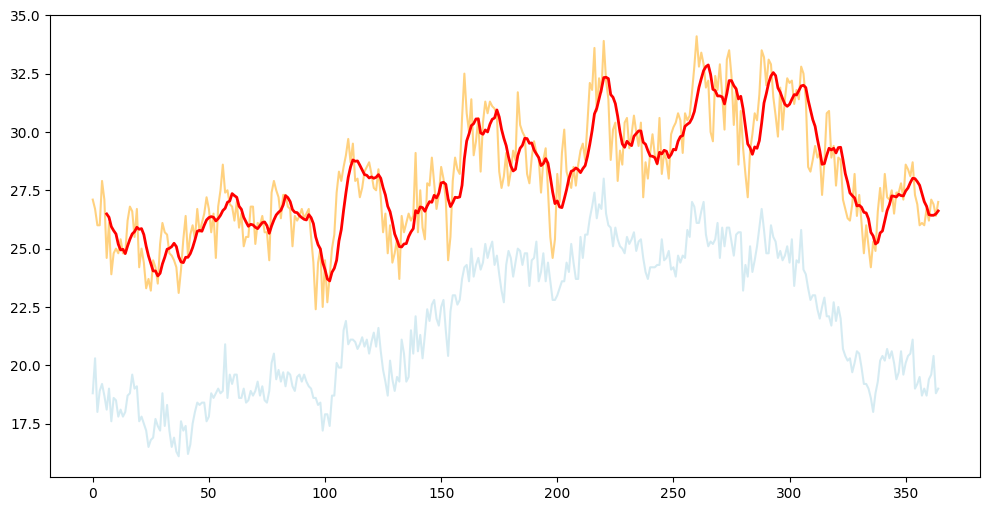

In [37]:
# B.2 Graphique
plt.figure(figsize=(12, 6))

# On coupe les 6 premiers jours pour les x (dates) afin d'aligner avec moy_glissante
x_jours = np.arange(len(tmax))
plt.plot(x_jours, tmax, color='orange', alpha=0.5, label='Tmax quotidienne')
plt.plot(x_jours, tmin, color='lightblue', alpha=0.5, label='Tmin quotidienne')
plt.plot(x_jours[6:], moy_glissante, color='red', linewidth=2, label='Moyenne glissante Tmax (7 jours)')


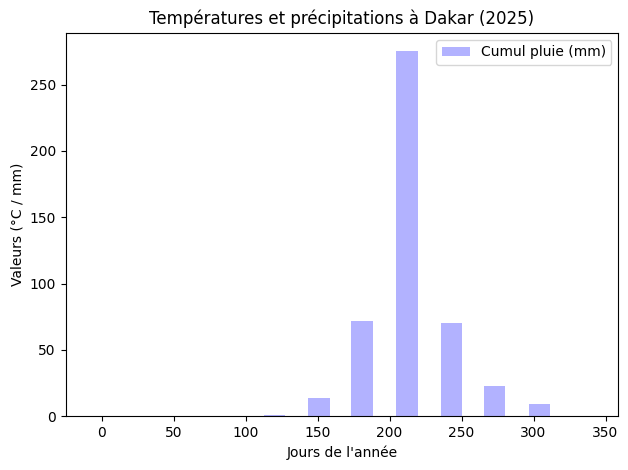

In [39]:
# Calcul du cumul mensuel des pluies
pluie_par_mois = np.bincount(mois - 1, weights=pluie)

# Pour le diagramme en barres, on superpose les cumuls mensuels sur des abscisses espacées
jours_debut_mois = [0, 31, 59, 90, 120, 151, 181, 212, 243, 273, 304, 334] # approximations
plt.bar(jours_debut_mois, pluie_par_mois, width=15, color='blue', alpha=0.3, label='Cumul pluie (mm)')

plt.title("Températures et précipitations à Dakar (2025)")
plt.xlabel("Jours de l'année")
plt.ylabel("Valeurs (°C / mm)")
plt.legend()
plt.tight_layout()
plt.show()